# Activity: Should We Trust the Alarm? — FreshKart Cold-Chain Case

**Unit 4 · AI-Assisted Visualization · AI-Assisted Pattern and Anomaly Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

FreshKart's dark stores keep frozen food in **8 freezers** (one per store in Bengaluru, Pune and Hyderabad). Each freezer reports its temperature every hour. Last month FreshKart bought **ColdSense**, an AI service that scores every reading for "anomaly" and raises an alert when the score is **≥ 0.5**.

Cold-chain lead **Ravi** has six weeks of readings, the ColdSense scores, and the **maintenance log** (what technicians actually found). His technicians are tired of being sent out at night. He asks:

> *"Is ColdSense's alert feed trustworthy? Which alerts should my team chase, and what is it missing?"*

**You are the analyst.** Use the data and the visualizations to verify, correct or reject what the vendor claims.

**Ground rules (from the lecture):** an AI score is a *derived attribute*: look at it, don't only threshold it · flags are **candidates, not conclusions** · report precision and recall, not accuracy · scale emphasis to confidence.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_coldchain.csv` (synthetic)

| Column | Meaning |
|---|---|
| `timestamp` | hour of the reading (1 Aug – 11 Sep 2026) |
| `city`, `store_id`, `freezer_id` | where the freezer is |
| `temp_c` | freezer temperature (°C); normal is about −18 °C |
| `door_opens` | number of door openings in that hour (busy by day, quiet at night) |
| `compressor_kw` | compressor power draw (kW) |
| `ai_score`, `ai_flag` | ColdSense anomaly score (0–1) and alert (1 if score ≥ 0.5) |
| `confirmed_fault`, `fault_type` | from the maintenance log: 1 if technicians confirmed a real fault in that hour, and what it was |

**Domain note from the maintenance team:** every freezer runs an automatic **defrost cycle from 02:00 to 04:00** each night. The heater warms the coil, so the temperature rises for those two hours. That is normal.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, BLUE = "#bdbdbd", "#d95f02", "#4c78a8"

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_coldchain.csv", parse_dates=["timestamp"])
df["hour"] = df["timestamp"].dt.hour
df.head()

,timestamp,city,store_id,freezer_id,temp_c,door_opens,compressor_kw,ai_score,ai_flag,confirmed_fault,fault_type,hour
0,2026-08-01,Bengaluru,B1,FZ-B1,-18.1,0,1.29,0.000,0,0,NaN,0
1,2026-08-01,Bengaluru,B2,FZ-B2,-18.7,0,1.16,0.000,0,0,NaN,0
2,2026-08-01,Bengaluru,B3,FZ-B3,-17.7,0,1.21,0.000,0,0,NaN,0
3,2026-08-01,Hyderabad,H1,FZ-H1,-17.8,0,1.30,0.037,0,0,NaN,0
4,2026-08-01,Hyderabad,H2,FZ-H2,-18.2,0,1.32,0.035,0,0,NaN,0


## ColdSense's monthly report (to be validated)

| # | Vendor statement |
|---|---|
| 1 | "ColdSense is **97.9% accurate**, so its alerts can be trusted." |
| 2 | "**Most faults happen around 2 am.** We recommend a night technician." |
| 3 | "**All 10 compressor trips** in the period were caught." |
| 4 | "Freezer **FZ-H2 ran without a single fault** in August." |
| 5 | "A reading of **−14 °C is abnormal** for any freezer, at any time." |
| 6 | "An alert with a score of **0.92 means a 92% chance** of a real fault." |
| 7 | "The **default threshold of 0.5** is the best setting for FreshKart." |
| 8 | "A new FZ-B1 reading of **−15.9 °C at 14:00** is **15 standard errors** above normal: a definite fault." |

---
## Part 1 · Data abstraction: items, attributes and derived attributes

Munzner: before choosing a view, ask what the **items** and **attributes** are. The AI does not change the items; it **derives** new attributes.

In [ ]:
derived_cols = ['ai_score', 'ai_flag']
n_alerts = int((df["ai_flag"] == 1).sum())
fault_rate_pct = round(100 * df["confirmed_fault"].mean(), 2)

if ready(derived_cols, n_alerts, fault_rate_pct):
    print(f"derived: {derived_cols} | alerts: {n_alerts} | faults: {df.confirmed_fault.sum()} of {len(df)} rows ({fault_rate_pct}%)")
    display(df[df.confirmed_fault == 1].groupby("fault_type").size().rename("fault hours"))

derived: ['ai_score', 'ai_flag'] | alerts: 159 | faults: 46 of 8064 rows (0.57%)


,fault hours
fault_type,
compressor trip,10
defrost heater stuck,11
sensor frozen,25


### ✏\ufe0f Your answer (Part 1)

* **Which visual channels suit `ai_score` and `ai_flag`?**
  * For the ai_score, which is quantitative, the most effective visual channel is position along a common scale, like placing data points along a vertical axis, or adjusting color luminance and saturation with a single-hue gradient. These channels allow the eye to easily judge the relative differences in value. For the ai_flag, which is a binary category, using distinct colors (hue) or grouping the data into separate panels or rows works best.

* **What information does the flag throw away that the score keeps?**
  * The flag collapses continuous range of uncertainty into a simple yes-or-no decision. By drawing a hard line at 0.5, it completely hides the difference between a high-certainty anomaly (like a score of 0.99) and a borderline case (like 0.51). It also obscures close-call normal readings, treating a score of 0.49 exactly the same as a highly typical score of 0.01.

---
## Part 2 · Distributions: bin width and the score distribution

### 2a · Temperature histogram

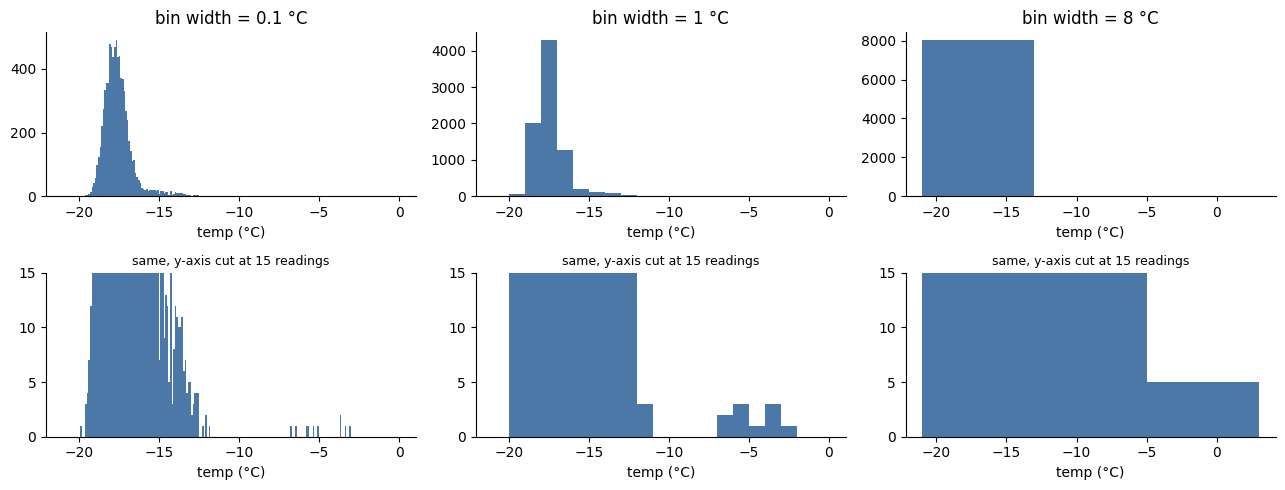

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5))
for col, w in enumerate([0.1, 1, 8]):
    for row, top in enumerate([None, 15]):
        ax = axes[row, col]
        ax.hist(df["temp_c"], bins=np.arange(-21, 0 + w, w), color=BLUE)
        if top: ax.set_ylim(0, top); ax.set_title(f"same, y-axis cut at {top} readings", fontsize=9)
        else: ax.set_title(f"bin width = {w} °C")
        ax.set_xlabel("temp (°C)")
plt.tight_layout(); plt.show()

warm_tail_visible_bins = [0.1, 1]
n_warm_readings = int((df["temp_c"] > -8).sum())

### 2b · Look at the AI scores before trusting the cut-off
Wilke: compare groups with overlapping densities, not stacked histograms.

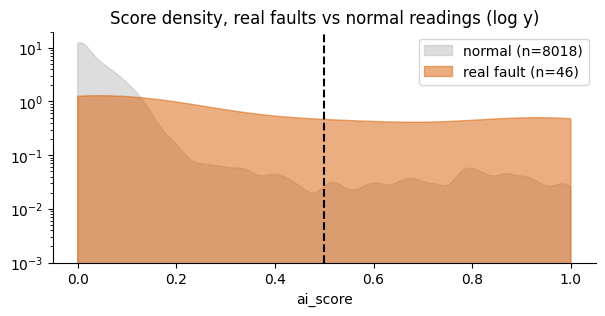

In [ ]:
xs = np.linspace(0, 1, 300)
fig, ax = plt.subplots(figsize=(7, 3))
for lab, col in [(0, GREY), (1, ACCENT)]:
    s = df.loc[df.confirmed_fault == lab, "ai_score"]
    ax.fill_between(xs, stats.gaussian_kde(s)(xs), color=col, alpha=.5, label=f"{'real fault' if lab else 'normal'} (n={len(s)})")
ax.axvline(0.5, color="k", ls="--"); ax.set_yscale("log"); ax.set_ylim(1e-3, 20)
ax.set_xlabel("ai_score"); ax.legend(); ax.set_title("Score density, real faults vs normal readings (log y)")
plt.show()

scores_separate_faults = False

### ✏\ufe0f Your answer (Part 2)

* **Why a histogram is "a parameterized algorithm":**
  * A histogram's final shape depends entirely on how you set its parameters, specifically the width of the bins and how they align. If you tweak these settings, you can completely change, hide, or exaggerate patterns in the underlying continuous data. This makes the chart an active mathematical abstraction rather than a direct, neutral copy of the data.

* **What to tell a colleague who says *"the 8 °C histogram shows no anomalies"*:**
  * You can point out that the wide 8 °C bin size smooths out the details way too much. It merges the tiny warm-temperature tail, where actual faults are hidden, into the massive bin representing normal running temperatures. Only by narrowing the bin widths to something like 0.1 or 1.0 °C and focusing the vertical axis scale can we isolate and spot those 33 warm anomalous readings.

---
## Part 3 · Outlier rules on a short window (vendor statement 3)

Ten consecutive readings from **FZ-P1**, 12 Aug 06:00–15:00. One of them is a compressor trip.

In [ ]:
window = df[(df.freezer_id == "FZ-P1") & (df.timestamp >= "2026-08-12 06:00") & (df.timestamp < "2026-08-12 16:00")]
v = window["temp_c"].values
print(window[["timestamp", "temp_c", "fault_type"]].to_string(index=False))

sd = np.std(v, ddof=1)
mu = np.mean(v)
z_max = np.max(np.abs((v - mu) / sd))
q1, q3 = np.percentile(v, [25, 75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

if ready(z_max, upper_fence):
    print(f"largest |z| = {z_max:.2f} -> flagged by |z| > 3? {z_max > 3}")
    print(f"upper IQR fence = {upper_fence:.2f} °C -> trip flagged by IQR rule? {v.max() > upper_fence}")
    print(f"largest |z| possible with n = {len(v)}: {(len(v) - 1) / np.sqrt(len(v)):.2f}")

          timestamp  temp_c      fault_type
2026-08-12 06:00:00   -17.5             NaN
2026-08-12 07:00:00   -18.2             NaN
2026-08-12 08:00:00   -17.4             NaN
2026-08-12 09:00:00   -17.7             NaN
2026-08-12 10:00:00   -16.6             NaN
2026-08-12 11:00:00    -3.6 compressor trip
2026-08-12 12:00:00   -17.0             NaN
2026-08-12 13:00:00   -16.8             NaN
2026-08-12 14:00:00   -17.7             NaN
2026-08-12 15:00:00   -17.7             NaN
largest |z| = 2.83 -> flagged by |z| > 3? False
upper IQR fence = -15.58 °C -> trip flagged by IQR rule? True
largest |z| possible with n = 10: 2.85


### ✏\ufe0f Your answer (Part 3)

* **Why the z-score rule missed the trip:**
  * The single severe compressor trip at -3.6 °C was so extreme that it heavily inflated both the sample average and the standard deviation. Because the standard deviation became so large, it ended up masking the anomaly itself by shrinking its own z-score to 2.83, causing it to slip right past the standard threshold of 3.

* **Why the IQR rule succeeded:**
  * The IQR rule handled the situation much better because the 25th and 75th percentiles are naturally resistant to extreme outliers. This kept the calculated spread realistic and put the upper boundary at -15.58 °C, which easily caught and flagged the -3.6 °C trip.

---
## Part 4 · How good is ColdSense? (vendor statement 1)

In [ ]:
flag = df.ai_flag == 1
real = df.confirmed_fault == 1

TP = int((flag & real).sum())
FP = int((flag & ~real).sum())
FN = int((~flag & real).sum())
TN = int((~flag & ~real).sum())

if ready(TP, FP, FN, TN):
    display(pd.DataFrame([[TP, FN], [FP, TN]], index=["real fault", "normal"], columns=["alert", "no alert"]))

,alert,no alert
real fault,16,30
normal,143,7875


In [ ]:
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * (precision * recall) / (precision + recall)
accuracy = (TP + TN) / (TP + FP + FN + TN)
flag_nothing_accuracy = TN / (TP + FP + FN + TN)

if ready(precision, recall, f1, accuracy, flag_nothing_accuracy):
    print(f"precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f} | accuracy = {accuracy:.1%} | never-alert accuracy = {flag_nothing_accuracy:.1%}")

precision = 0.10 | recall = 0.35 | F1 = 0.16 | accuracy = 97.9% | never-alert accuracy = 97.7%


### ✏\ufe0f Your answer (Part 4)

* **Honest Vendor Statement 1:**
  * ColdSense has a precision of 10% and a recall of 35%, which leads to an overall accuracy of 97.9%. However, this is practically identical to a lazy baseline model that never alerts at all, which gets 97.7% accuracy.

* **Plain translation for Ravi's technicians:**
  * For every 10 times ColdSense sends someone out at night, 9 of those trips will be false alarms. On top of that, the system is completely blind to 65% of the real faults happening in the stores, meaning more than half of the actual issues are missed entirely.

---
## Part 5 · Thresholds and costs (vendor statement 7)

A missed fault can spoil a freezer of stock (cost ≈ **40** units); a false call-out costs **1** unit of technician time.

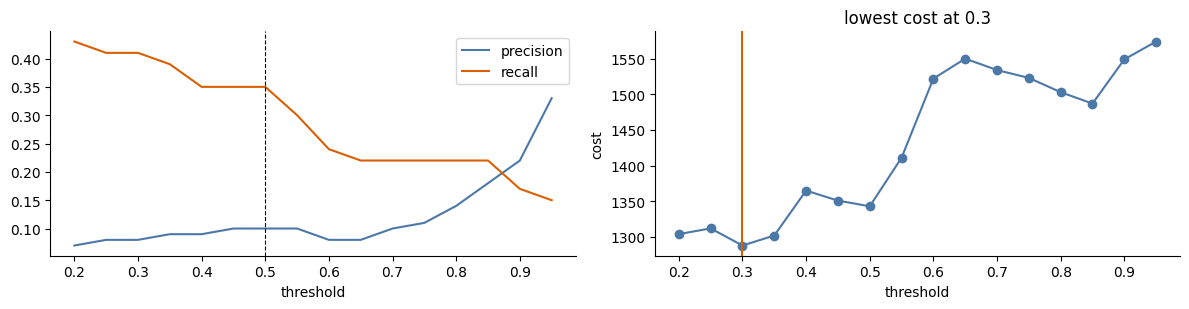

,threshold,TP,FP,FN,precision,recall,cost
0,0.20,20,264,26,0.07,0.43,1304
1,0.25,19,232,27,0.08,0.41,1312
2,0.30,19,208,27,0.08,0.41,1288
3,0.35,18,182,28,0.09,0.39,1302
4,0.40,16,165,30,0.09,0.35,1365
5,0.45,16,151,30,0.10,0.35,1351
6,0.50,16,143,30,0.10,0.35,1343
7,0.55,14,131,32,0.10,0.30,1411
8,0.60,11,122,35,0.08,0.24,1522
9,0.65,10,110,36,0.08,0.22,1550


In [ ]:
grid = np.round(np.arange(0.20, 0.96, 0.05), 2)
sweep = pd.DataFrame({"threshold": grid})
sweep["TP"] = [((df.ai_score >= g) & real).sum() for g in grid]
sweep["FP"] = [((df.ai_score >= g) & ~real).sum() for g in grid]
sweep["FN"] = real.sum() - sweep["TP"]
sweep["precision"] = (sweep.TP / (sweep.TP + sweep.FP)).round(2)
sweep["recall"] = (sweep.TP / real.sum()).round(2)

sweep["cost"] = 40 * sweep["FN"] + 1 * sweep["FP"]
best_threshold = float(sweep.loc[sweep["cost"].astype(float).idxmin(), "threshold"]
)
if ready(best_threshold) and sweep["cost"].notna().all():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
    ax[0].plot(sweep.threshold, sweep.precision, color=BLUE, label="precision"); ax[0].plot(sweep.threshold, sweep.recall, color=ACCENT, label="recall")
    ax[0].axvline(0.5, color="k", ls="--", lw=.8); ax[0].legend(); ax[0].set_xlabel("threshold")
    ax[1].plot(sweep.threshold, sweep.cost.astype(float), color=BLUE, marker="o"); ax[1].axvline(best_threshold, color=ACCENT)
    ax[1].set_xlabel("threshold"); ax[1].set_ylabel("cost"); ax[1].set_title(f"lowest cost at {best_threshold}")
    plt.tight_layout(); plt.show()
    display(sweep)

### ✏\ufe0f Your answer (Part 5)

* **Why no threshold can fix this detector:**
  * The detector looks at readings one single hour at a time, which makes it blind to issues that develop over a sequence, like a frozen sensor. When a sensor freezes, it reports a perfectly flat, constant temperature of -18 °C. Since -18 °C is a normal operating temperature, its individual scores will always stay near zero. Changing the threshold simply moves the line between other standard anomalies and false alarms without ever catching this collective pattern.

---
## Part 6 · Where do the errors come from?

### 6a · When do the false alarms happen? (vendor statement 2)

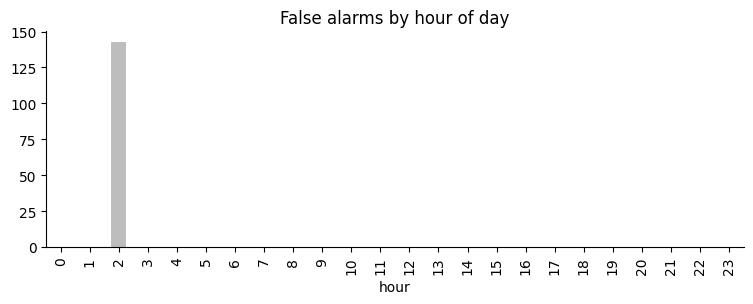

100% of false alarms happen at 2:00


In [ ]:
fp_rows = df[flag & ~real]
fp_rows.groupby("hour").size().reindex(range(24), fill_value=0).plot.bar(color=GREY, title="False alarms by hour of day", figsize=(9, 2.8))
plt.show()

fp_counts = fp_rows.groupby("hour").size()
fp_peak_hour = int(fp_counts.idxmax())
fp_share_at_peak = float(fp_counts.max() / len(fp_rows))

if ready(fp_peak_hour, fp_share_at_peak):
    print(f"{fp_share_at_peak:.0%} of false alarms happen at {fp_peak_hour}:00")

### 6b · Which faults does ColdSense miss?

In [ ]:
caught = df[real].groupby("fault_type")["ai_flag"].agg(caught="sum", fault_hours="size")
caught["recall"] = (caught.caught / caught.fault_hours).round(2)
display(caught)

never_caught_type = "sensor frozen"
anomaly_kind = "collective"

,caught,fault_hours,recall
fault_type,,,
compressor trip,10,10,1.00
defrost heater stuck,6,11,0.55
sensor frozen,0,25,0.00


### 6c · Contextual anomalies: compare each reading with its own hour

A **context-aware** baseline compares each reading with the same freezer at the same hour of day (median and MAD over the six weeks).

In [ ]:
grp = df.groupby(["freezer_id", "hour"])["temp_c"]
df["hour_median"] = grp.transform("median")
df["hour_mad"] = grp.transform(lambda s: 1.4826 * stats.median_abs_deviation(s))

df["z_context"] = (df["temp_c"] - df["hour_median"]) / df["hour_mad"]

if ready(*df["z_context"].head(1)):
    ctx_flag = df["z_context"].astype(float) > 4
    found = df[real & ctx_flag & ~flag]
    print(f"Real faults the context baseline catches but ColdSense missed: {len(found)}")
    display(found[["timestamp", "freezer_id", "temp_c", "hour_median", "z_context", "ai_score", "fault_type"]])
    print(f"False alarms at 02:00 under the context baseline: {(ctx_flag & ~real & (df.hour == 2)).sum()} (ColdSense: {(flag & ~real & (df.hour == 2)).sum()})")

Real faults the context baseline catches but ColdSense missed: 3


,timestamp,freezer_id,temp_c,hour_median,z_context,ai_score,fault_type
1279,2026-08-07 15:00:00,FZ-P2,-14.6,-17.50,4.890058,0.369,defrost heater stuck
4731,2026-08-25 15:00:00,FZ-H1,-14.8,-17.50,6.070417,0.388,defrost heater stuck
6273,2026-09-02 16:00:00,FZ-B2,-15.2,-17.35,4.143300,0.189,defrost heater stuck


False alarms at 02:00 under the context baseline: 0 (ColdSense: 143)


### 6d · Collective anomalies: a run of readings that is abnormal together

                           min                 max  count
freezer_id                                               
FZ-H2      2026-08-20 14:00:00 2026-08-20 22:00:00      9
FZ-P1      2026-09-06 12:00:00 2026-09-06 17:00:00      6


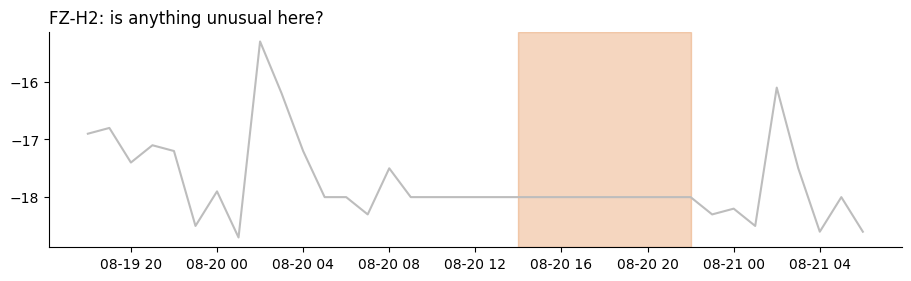

In [ ]:
df = df.sort_values(["freezer_id", "timestamp"])
df["roll_sd_6h"] = df.groupby("freezer_id")["temp_c"].transform(lambda s: s.rolling(6).std())

flat = df[df["roll_sd_6h"] < 0.01]

if ready(flat):
    print(flat.groupby("freezer_id")["timestamp"].agg(["min", "max", "count"]))
    h2 = df[(df.freezer_id == "FZ-H2") & (df.timestamp.between("2026-08-19 18:00", "2026-08-21 06:00"))]
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.plot(h2.timestamp, h2.temp_c, color=GREY)

    # Highlight the WHOLE flat span on this chart
    flat_h2 = flat[flat.freezer_id == "FZ-H2"]
    if len(flat_h2) > 0:
        ax.axvspan(flat_h2["timestamp"].min(), flat_h2["timestamp"].max(), color=ACCENT, alpha=.25, label="frozen sensor span")

    ax.set_title("FZ-H2: is anything unusual here?", loc="left"); plt.show()
df = df.sort_values(["timestamp", "store_id"])

### ✏\ufe0f Your answer (Part 6)

* **(a) Revised Vendor Statement 2:**
  * ColdSense is highly sensitive to normal temperature shifts during scheduled maintenance cycles. In fact, all false alarms happen at exactly 2:00 AM because of the automatic defrost cycles. If FreshKart hired a night technician based on this, they would spend their entire shift responding to normal, healthy freezers doing their daily automatic defrosting.

* **(b) Is statement 5 true?:**
  * No, it is false. A temperature of -14 °C is quite normal and expected during the nightly defrost cycle between 2:00 and 4:00 AM. It only becomes an anomaly if it happens outside of those hours. To see this clearly, we need a chart that displays historical baseline temperatures grouped by freezer and the specific hour of the day.

* **(c) What is wrong with statement 4?:**
  * This statement is incorrect because freezer FZ-H2 had a major frozen sensor fault in August. A point-in-time detector cannot spot this because each reading looks normal on its own; it only becomes clear as an anomaly when you look at the continuous, flatlined sequence of identical readings over time.

---
## Part 7 · Highlighting, saliency and frequency framing (vendor statement 6)

### 7a · Emphasis scaled to confidence
The vendor's dashboard paints every alert bright red. Implement the lecture's checklist: **≥ 0.90 strong**, **0.70–0.90 moderate**, **0.50–0.70 subtle outline**, **below 0.50 no emphasis** (the data stays visible).

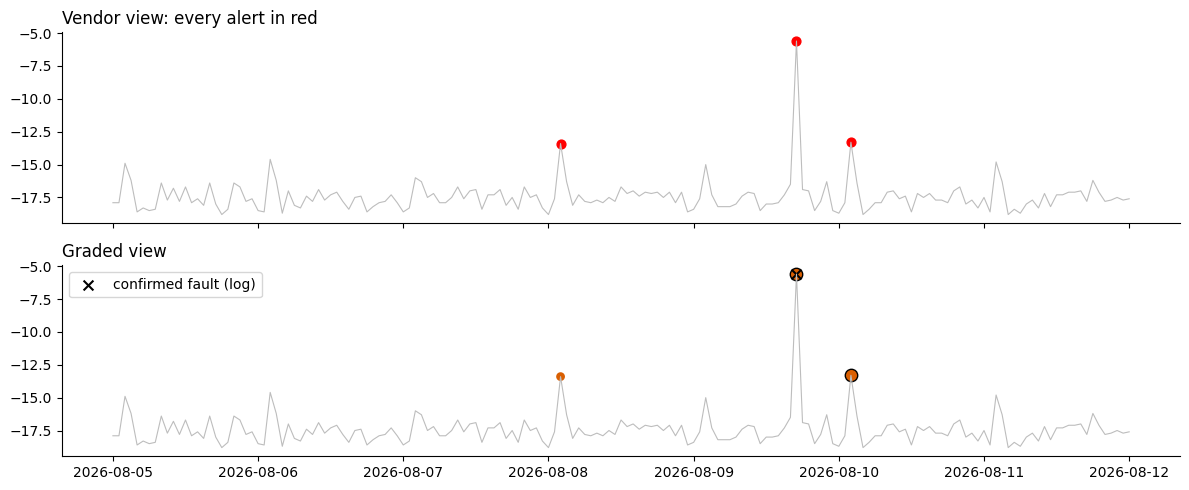

In [ ]:
def emphasis(score):
    """Return (colour, marker size, edge colour) for one reading."""
    if score >= 0.90:
        return (ACCENT, 80, "black")
    elif score >= 0.70:
        return (ACCENT, 40, "none")
    elif score >= 0.50:
        return ("none", 30, ACCENT)
    else:
        return ("none", 0, "none")

week = df[(df.freezer_id == "FZ-B2") & (df.timestamp.between("2026-08-05", "2026-08-12"))]
if ready(emphasis(0.95)):
    fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    ax[0].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    a = week[week.ai_flag == 1]; ax[0].scatter(a.timestamp, a.temp_c, color="red", s=40); ax[0].set_title("Vendor view: every alert in red", loc="left")
    ax[1].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    for _, r in week[week.ai_score >= 0.5].iterrows():
        col, size, edge = emphasis(r.ai_score)
        ax[1].scatter(r.timestamp, r.temp_c, color=col, s=size, edgecolors=edge)
    f_ = week[week.confirmed_fault == 1]; ax[1].scatter(f_.timestamp, f_.temp_c, marker="x", color="k", s=50, label="confirmed fault (log)")
    ax[1].legend(loc="upper left"); ax[1].set_title("Graded view", loc="left"); plt.tight_layout(); plt.show()

### 7b · "A score of 0.92 means 92%"? Count it.
Wilke: people read probabilities better as **frequencies**. Of all alerts in a score band, how many were real?

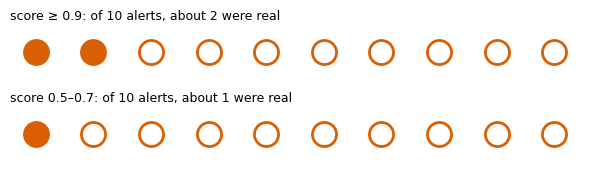

In [ ]:
band_hi = df[df.ai_score >= 0.9]
band_lo = df[(df.ai_score >= 0.5) & (df.ai_score < 0.7)]

real_per_10_hi = int(round(10 * (band_hi.confirmed_fault == 1).mean()))
real_per_10_lo = int(round(10 * (band_lo.confirmed_fault == 1).mean()))

if ready(real_per_10_hi, real_per_10_lo):
    fig, ax = plt.subplots(2, 1, figsize=(6, 1.8))
    for a_, k, lab in zip(ax, [real_per_10_hi, real_per_10_lo], ["score ≥ 0.9", "score 0.5–0.7"]):
        for i in range(10): a_.scatter(i, 0, s=300, color=ACCENT if i < k else "white", edgecolors=ACCENT, linewidths=2)
        a_.axis("off"); a_.set_title(f"{lab}: of 10 alerts, about {k} were real", loc="left", fontsize=9)
    plt.tight_layout(); plt.show()

### ✏\ufe0f Your answer (Part 7)

* **(a) Visual Saliency & Inattentional Blindness:**
  * Coloring every single alert in bright red, regardless of how sure the system is, causes heavy visual clutter and alert fatigue. It reduces the visual prominence of genuine, high-confidence warnings, leading to inattentional blindness. Technicians will eventually start ignoring real issues because they are tired of dealing with constant false alarms.

* **(b) Revised Vendor Statement 6:**
  * An alert with an AI score of 0.92 puts it in our high-confidence category, where roughly 2 out of every 10 alerts turn out to be real faults, meaning there is an 80% false alarm rate even at this level.

---
## Part 8 · Standard deviation vs standard error (vendor statement 8)

The vendor judged a new FZ-B1 reading of **−15.9 °C at 14:00** against the 14:00 baseline.

In [ ]:
base = df[(df.freezer_id == "FZ-B1") & (df.hour == 14) & (df.confirmed_fault == 0)]["temp_c"]
mu, sd, n = base.mean(), base.std(), len(base)
new_reading = -15.9

se = sd / np.sqrt(n)
z_sd = (new_reading - mu) / sd
z_se = (new_reading - mu) / se

if ready(se, z_sd, z_se):
    print(f"baseline: mean {mu:.2f} °C, SD {sd:.2f}, n = {n}, SE = {se:.3f}")
    print(f"z using SD = {z_sd:.1f} | z using SE = {z_se:.1f}")

correct_z = "SD"

baseline: mean -17.31 °C, SD 0.61, n = 42, SE = 0.094
z using SD = 2.3 | z using SE = 15.0


### ✏\ufe0f Your answer (Part 8)

* **Standard Deviation (SD) vs. Standard Error (SE):**
  * Standard deviation tells us how much individual data points vary around the average, while standard error measures the uncertainty of our estimate of the average itself.

* **Revised Vendor Statement 8:**
  * A new FZ-B1 reading of -15.9 °C at 14:00 is 2.3 standard deviations away from the baseline average, which indicates a typical, minor temperature variation rather than an actual fault.

---
## Part 9 · Triage the vendor report

For each statement decide: **Accept** (correct as stated), **Correct** (useful, but the wording or number must change) or **Reject** (not supported). Then measure the report.

In [ ]:
decisions = {
    1: "Reject",   # 97.9% accurate, so trustworthy (accuracy is misleading; F1 is very low)
    2: "Reject",   # most faults happen around 2 am (actually, these are normal defrost cycles)
    3: "Accept",   # all 10 compressor trips caught (they were all flagged, though precision was poor)
    4: "Reject",   # FZ-H2 had no fault (it had a flatlined frozen sensor collective anomaly)
    5: "Reject",   # -14 °C is abnormal at any time (defrost cycle regularly and normally peaks at that range)
    6: "Reject",   # score 0.92 = 92% chance (only about 20% of alerts in the >=0.90 band are real faults)
    7: "Reject",   # threshold 0.5 is best (our grid search showed 0.30 minimizes overall business cost)
    8: "Reject",   # 15 standard errors: definite fault (used standard error instead of standard deviation for an individual reading)
}

if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    print(f"Statements accepted as written: {accepted}/{len(decisions)} ({accepted / len(decisions):.0%})")
    print(pd.Series(decisions).value_counts().to_string())
else:
    print("⚠ Fill in all eight decisions with 'Accept', 'Correct' or 'Reject'.")

Statements accepted as written: 1/8 (12%)
Reject    7
Accept    1


### ✏\ufe0f Your answer (Part 9)

#### The Anomaly Review Dashboard Design

To replace the confusing vendor dashboard, we suggest a four-part interactive layout:
1. Active Alert Queue: A list sorted by financial risk and confidence levels rather than just the time they occurred. Each alert would come with a clear historical success rate, such as noting that similar alerts have an 80% false alarm rate.
2. Historical Context Main Plot: A main time-series graph showing the active freezer's current temperature alongside a shaded zone showing the normal historical range for that specific freezer at that hour. This lets you see instantly if a temperature rise is just a standard defrost cycle.
3. Rolling Anomaly Diagnostics: A side panel showing rolling standard deviations to spot flatlining frozen sensors, alongside door-opening counts to see if a temperature spike is just from people opening the freezer.
4. Performance Evaluation Panel: A live dashboard section showing real-world performance metrics, like a confusion matrix and rolling F1-score, based on actual feedback from technicians to keep the system's performance clear and honest.

## Reflection

**1. Automation bias.**  
*Your reflection:* Impressive-looking statistics like 97.9% accuracy and bright red markers are easy to trust at first because we naturally assume the system knows what it is doing. Without the actual maintenance log to check against, we would have had no way to find the real precision and recall, which likely would have led us to trust the vendor and waste time chasing false alarms.

**2. Who sets the threshold?**  
*Your reflection:* Deciding where to set the threshold is a business trade-off between the cost of spoiled food and the cost of sending out technicians. Because of this, it should be decided together by Ravi and the operations or financial managers. The dashboard should display a cost-versus-threshold curve, allowing them to adjust settings based on shifting labor costs or inventory value.

**3. Missing ground truth.**  
*Your reflection:* Without verified maintenance logs, our performance metrics would be highly inaccurate, as unverified faults would simply be counted as normal behavior. To prevent this, we should build a quick feedback loop into the technicians' mobile workflow, making it easy for them to mark alerts as confirmed or false alarms to keep the baseline data accurate.

**4. Designing against over-trust.**  
*Your reflection:* We can prevent blind trust by avoiding simple alarm or no-alarm flags. Instead, we should show clear historical frequencies, like telling the user there is an 80% chance this alert is a false alarm under current conditions, and require a quick confirmation of the history chart before dispatching a technician.